# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()` (every metamodel set in
   `metamodel.sets`: one PCA + GP per group of output sites, same SnapWave cases
   and MDA)
2. **Validate** — `val.sweep(goal, metamodel=…)` for metrics;
   `val.validate(goal, n, metamodel=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Holdout metrics and plots
include **`hs`, `tp`, `dir`, `spr`** (`spr` via PCA; `tp` raw). Use
`mm.report_training_data(goal, n=450)` or `mm.load_fit_summary(goal, mm_set, 450)` after
fit to inspect site filter and PCA site retention.

In [1]:
import matplotlib.pyplot as plt
from utils import metamodel as mm
from utils import validation as val
from utils.config import METAMODEL, load_goals, mda_max_points

In [2]:
goals = list(load_goals().keys())
mm_set = "isobaths"  # metamodel set to validate and plot (see metamodel.sets)
candidates = METAMODEL["mda_candidates"]
metrics = METAMODEL["validation"]["metrics_variables"]
site_filter = METAMODEL["site_filter"]

print(f"goals      : {goals}")
print(f"sets       : {METAMODEL['sets']} (plotting {mm_set!r})")
print(f"candidates : {candidates}")
print(f"metrics    : {metrics}")
print(f"MDA max    : {mda_max_points()} (test cases = plausible cases - max)")
for key, threshold in site_filter.items():
    if key.endswith("_ratio_max"):
        var = key[:-10]
        print(
            f"{var} filter : > {threshold} x {var}_forcing removed before PCA (site_filter)"
        )
    elif key.endswith("_max"):
        var = key[:-4]
        print(f"{var} filter : > {threshold} removed before PCA (site_filter)")
    elif key.endswith("_min"):
        var = key[:-4]
        print(f"{var} filter : < {threshold} removed before PCA (site_filter)")
print("PCA NaN    : safety net only (sites are wet; zero-energy fields filled with the forcing)")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']
sets       : {'buoys': {'sites': 'buoy'}, 'isobaths': {'sites': 'isobath'}} (plotting 'isobaths')
candidates : [50, 100, 200, 350, 550]
metrics    : ['hs', 'tp', 'dir', 'spr']
MDA max    : 550 (test cases = plausible cases - max)
hs filter : > 3.0 x hs_forcing removed before PCA (site_filter)
tp filter : < 0.5 removed before PCA (site_filter)
hs_nan filter : > 0.01 removed before PCA (site_filter)
PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)


## 1 · Fit

In [3]:
# All goals:
# mm.fit_all(gp_epochs=1500)

## 2 · Validate

In [4]:
# Metrics for every MDA size → outputs/goal_01/{mm_set}/validation_metrics.csv
metrics = val.sweep(2, metamodel=mm_set)
metrics.head()

,goal,metamodel,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label
0,2,isobaths,50,79,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",5m,isobath,5m,hs,Hs,2607,-0.004483,0.221659,0.404759,0.247545,0.950691,0.902041,SWAN,Metamodel
1,2,isobaths,50,79,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",5m,isobath,5m,tp,Tp,2370,-0.019326,0.830491,0.078124,0.075352,0.959423,0.917892,SWAN,Metamodel
2,2,isobaths,50,79,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",5m,isobath,5m,dir,Dir,2607,-0.251678,7.364651,NaN,NaN,NaN,0.934468,SWAN,Metamodel
3,2,isobaths,50,79,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",5m,isobath,5m,spr,Spr,2607,0.477997,6.913412,0.464870,0.408831,0.657702,0.246381,SWAN,Metamodel
4,2,isobaths,50,79,"{'hs': 0.99, 'tp': 0.99, 'dir': 0.99, 'spr': 0...",10m,isobath,10m,hs,Hs,7031,-0.005481,0.244802,0.378956,0.228072,0.959498,0.918378,SWAN,Metamodel


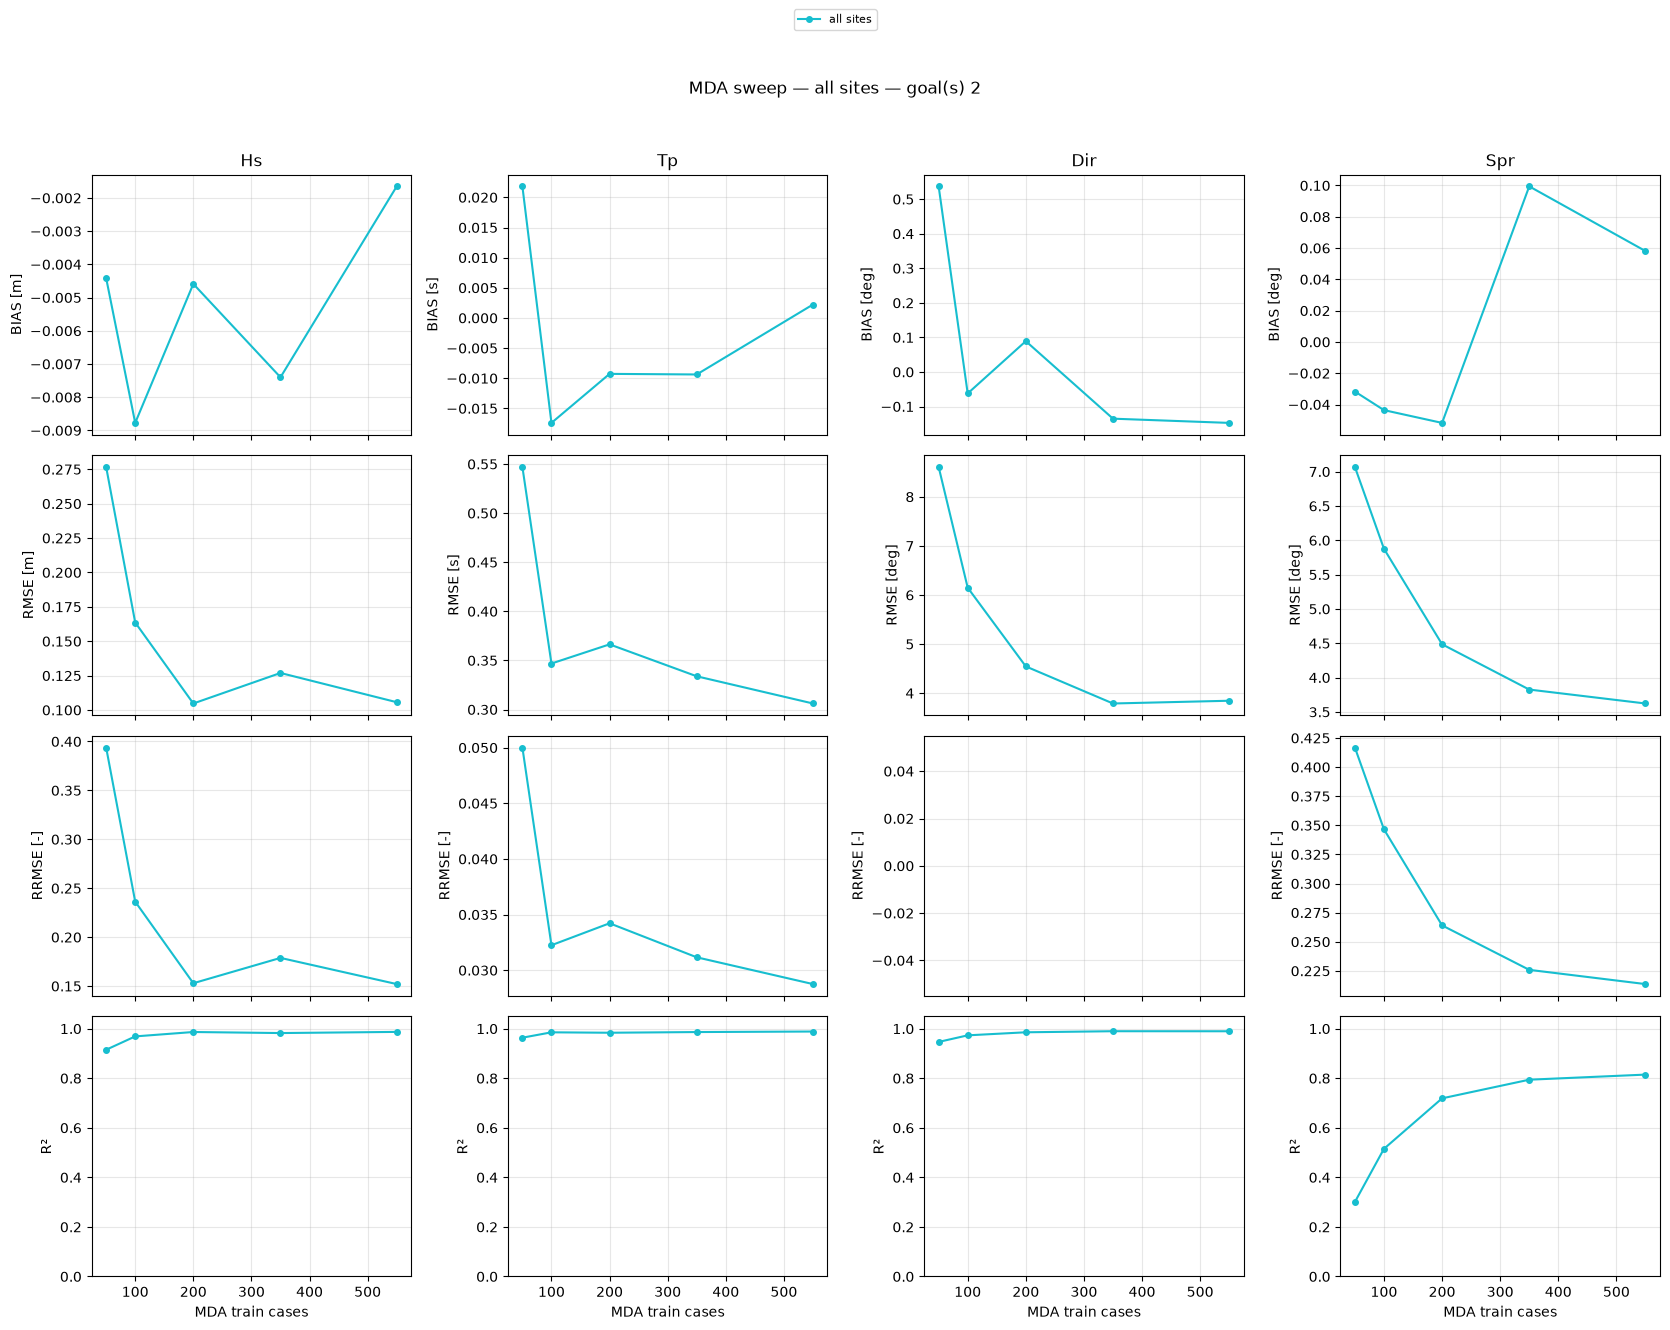

In [5]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3 · Plot

In [6]:
n = 550  # MDA size to plot
result = val.validate(2, n, metamodel=mm_set)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

['5m', '10m', '20m']

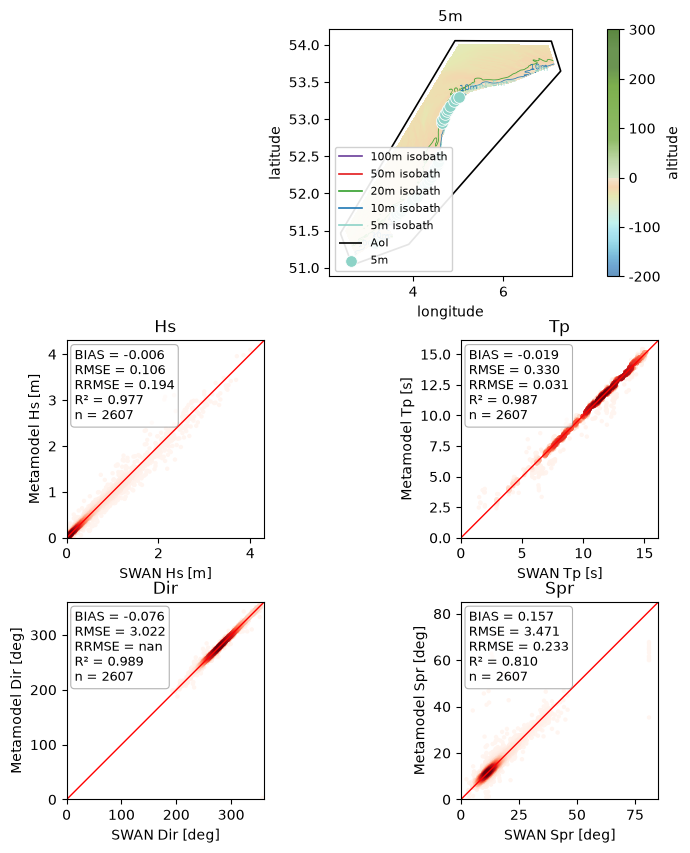

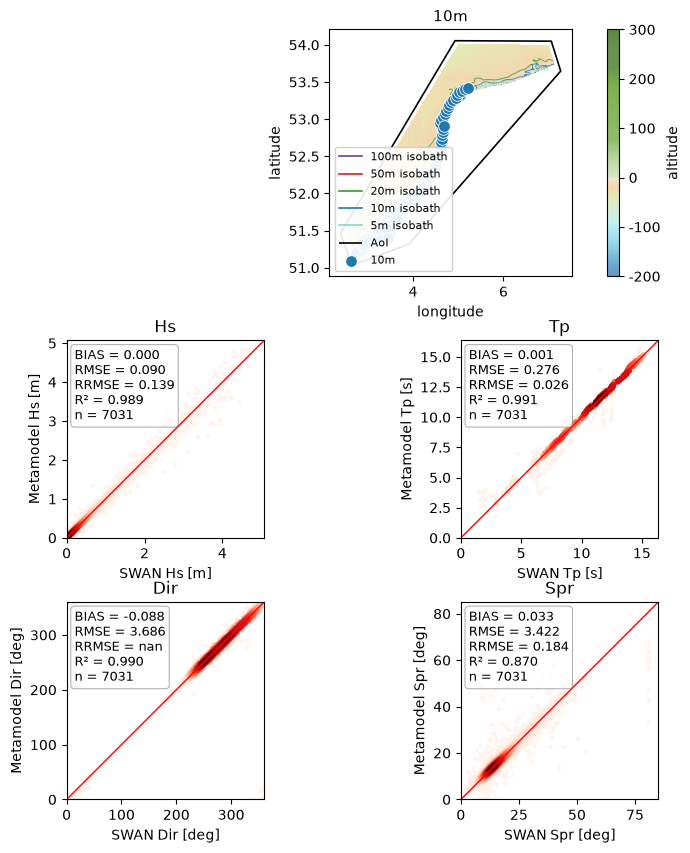

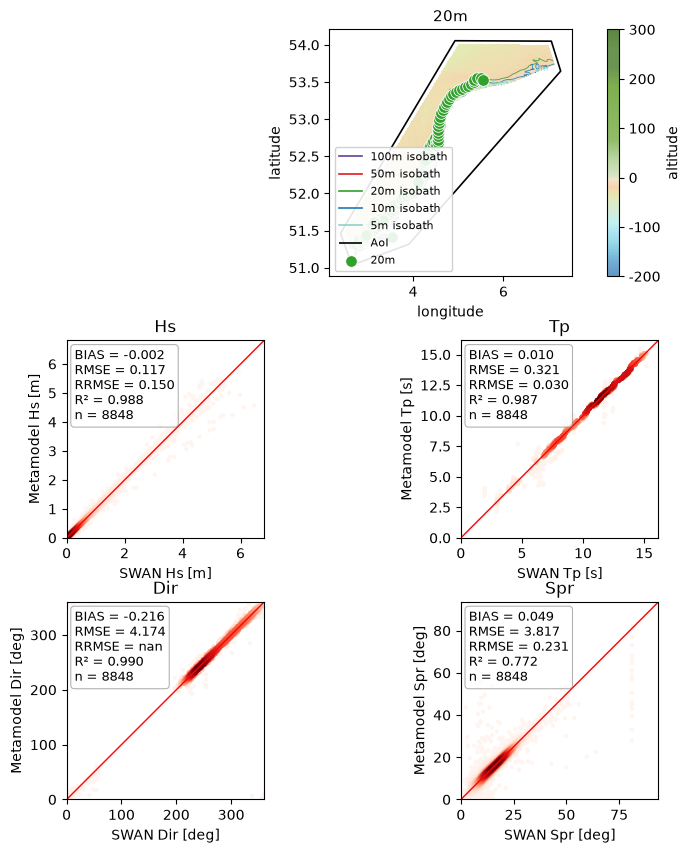

In [7]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all(cmap="Reds"):
    plt.show()

## All goals

In [8]:
all_metrics = val.sweep_all()  # every goal and metamodel set
all_metrics

,goal,metamodel,mda_candidate,n_test_cases,pca_variances,group,site_source,site_label,variable,label,n,bias,rmse,rrmse,si,r,r2,reference_label,estimate_label
0,1,buoys,50,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,hs,Hs,79,2.226881e-02,2.823492e-01,1.823816e-01,1.535813e-01,0.957946,0.917141,SnapWave,Metamodel
1,1,buoys,50,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,tp,Tp,79,2.569258e-07,1.016455e-06,9.545079e-08,8.973779e-08,1.000000,1.000000,SnapWave,Metamodel
2,1,buoys,50,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,dir,Dir,79,1.750809e+00,1.501155e+01,NaN,NaN,NaN,0.965875,SnapWave,Metamodel
3,1,buoys,50,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_A2,buoy,waves,spr,Spr,79,1.033603e-01,6.463775e+00,2.499986e-01,2.303434e-01,0.806743,0.648168,SnapWave,Metamodel
4,1,buoys,50,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",buoy_AWG,buoy,waves,hs,Hs,79,2.378557e-03,1.340721e-02,1.443322e+00,5.459646e-01,0.807070,0.638886,SnapWave,Metamodel
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8195,10,isobaths,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",10m,isobath,10m,spr,Spr,9638,-1.694526e-01,4.060046e+00,1.070465e-01,9.853116e-02,0.967490,0.935717,SnapWave,Metamodel
8196,10,isobaths,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,hs,Hs,10823,2.386290e-03,7.894437e-02,3.093231e-01,1.056166e-01,0.993752,0.987360,SnapWave,Metamodel
8197,10,isobaths,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,tp,Tp,10823,7.564311e-08,9.531887e-07,9.125206e-08,8.798383e-08,1.000000,1.000000,SnapWave,Metamodel
8198,10,isobaths,550,79,"{'hs': 0.99, 'dir': 0.99, 'spr': 0.99}",20m,isobath,20m,dir,Dir,10823,-1.948098e-02,6.913050e+00,NaN,NaN,NaN,0.994035,SnapWave,Metamodel


In [9]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]

,goal,mda_candidate,site_label,rmse,r2,n
812,1,550,10m,0.086935,0.987208,9796
8192,10,550,10m,0.075948,0.981954,9796
1632,2,550,10m,0.074173,0.992665,9796
2452,3,550,10m,0.070236,0.991467,9796
3272,4,550,10m,0.068370,0.992518,9796
4092,5,550,10m,0.075604,0.991119,9796
4912,6,550,10m,0.074031,0.986717,9796
5732,7,550,10m,0.060913,0.990597,9796
6552,8,550,10m,0.070445,0.987718,9796
7372,9,550,10m,0.067749,0.990108,9796
